# Phase 3 — Washing-machine disaggregation from whole-house power

**Task:** estimate washing-machine (WM) power at 1-minute resolution using only the whole-house aggregate,
on the official cleaned REFIT data.

All logic is in [`wm_nilm.py`](wm_nilm.py) (`python3 phase3/wm_nilm.py` produces the same outputs).
Data loading reuses Phase 2's rules from `phase2/wm_eda.py` **read-only** — no Phase 2 output is changed.

| Output | Location |
|---|---|
| Tables | `outputs/tables/phase3/` |
| Figures | `outputs/figures/phase3/` |
| Model + run settings | `outputs/models/phase3/` |
| Test-period predictions | `Data/processed/phase3/test_predictions.parquet` |

In [1]:
import sys
from pathlib import Path
import pandas as pd
from IPython.display import Image, display

here = Path.cwd()
sys.path.insert(0, str(here if (here / "wm_nilm.py").exists() else here / "phase3"))
import wm_nilm as w

pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 40)
w.ensure_dirs()
print("Modelled houses:", w.MODEL_HOUSES, "| excluded:", w.EXCLUDED_HOUSES)

Modelled houses: [2, 7, 8, 9, 15] | excluded: {5: 'WM channel is probably a washer-dryer (model AEG L99695HWD; 5-9.5 h wash+dry periods). Training on it would teach the model that drying is washing.'}


## 1 · Feasibility and household selection

**Candidates:** the six Phase 2 houses (2, 5, 7, 8, 9, 15).

- **House 5 is excluded.** Its WM channel is probably a washer-dryer (Phase 2 DATA.md §2). Using it as a
  training target would teach the model that drying is washing, and using it as a test target would score the
  model against the wrong appliance.
- **Houses 2, 7, 8, 9, 15** have a dedicated WM channel whose readings are consistent with the aggregate
  (the WM exceeds the house total in well under 1% of minutes).

**Per-minute usability rules** (applied identically to every house):

1. Both the aggregate and the WM value must be present (Phase 2's 1-minute data, frozen readings already masked).
2. **Whole UTC days with ≥ 60 frozen-aggregate minutes are excluded.** See the evidence table below.
3. Minutes where the WM reads more than 100 W **above** the aggregate are excluded (a sub-meter cannot exceed
   the house total — a timing or sensor mismatch).

> **Assumption:** the `Issues` flag (sum of *all* sub-meters > aggregate) is not used as an exclusion rule. It
> describes the other sub-meters too, and the WM-specific inconsistency is handled by rule 3.

In [2]:
d = w.prepare()
w.frozen_wm_evidence(d)

,house,frozen_agg_minutes,wm_exact_zero_pct_during_frozen,wm_exact_zero_pct_usable,wm_active_pct_during_frozen,wm_active_pct_usable
0,2,6502,100.0,94.4,0.00,4.69
1,7,4827,99.4,74.7,0.31,8.33
2,8,7935,79.5,84.1,1.54,3.36
3,9,38443,97.9,90.2,0.00,2.83
4,15,6568,100.0,96.2,0.00,2.87


**Why whole days, not just the frozen aggregate minutes:** while the aggregate is frozen, the WM channel reads
*exactly 0 W* far more often than in normal periods (House 7: its usual ~0.4 W standby disappears), and almost
never shows activity. The logger itself appears to stall, so those WM "zeros" are **not real evidence that the
machine was off**. Keeping them would feed the model false negatives and inflate its test score with easy
zeros. House 9 is the extreme case (next cell and figure).

Excluded days per house:
house
2     13
7     11
8     23
9     36
15     8

House 9 excluded days:
 house    day_utc  frozen_agg_minutes  wm_valid_minutes
     9 2013-12-19                 404              1421
     9 2013-12-20                1431              1431
     9 2013-12-21                1438              1438
     9 2013-12-22                1440              1440
     9 2013-12-23                1437              1437
     9 2013-12-24                 742              1440
     9 2014-03-13                 397              1440
     9 2014-03-14                1424              1424
     9 2014-03-15                1440              1440
     9 2014-03-16                1440              1440
     9 2014-03-17                1433              1433
     9 2014-03-18                1435              1435
     9 2014-03-19                1437              1437
     9 2014-03-20                1440              1440
     9 2014-03-21                1440              1440
    

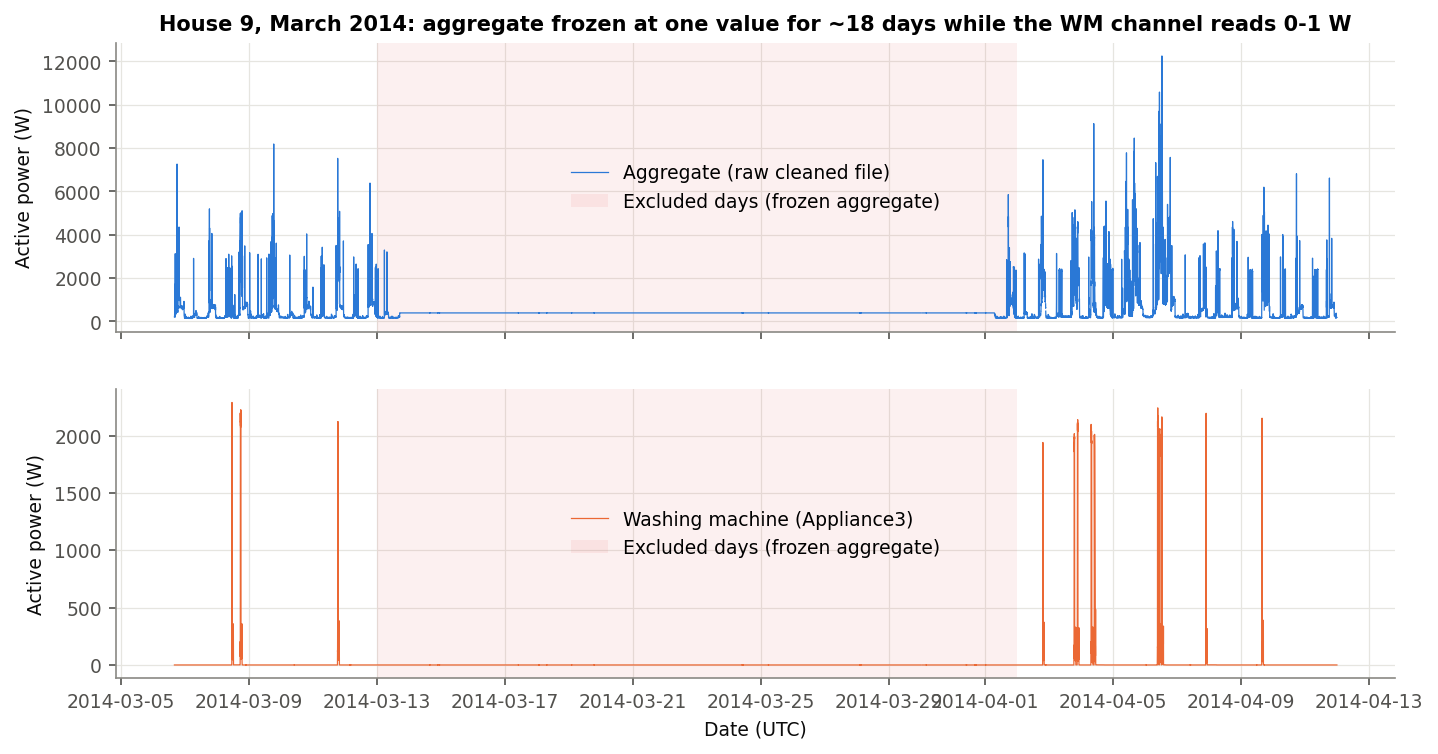

In [3]:
bad = w.bad_day_table(d["flags"])
print("Excluded days per house:"); print(bad.groupby("house").size().to_string())
print("\nHouse 9 excluded days:"); print(bad[bad.house == 9].to_string(index=False))
display(Image(filename=str(w.fig_house9_investigation())))

> **Limitation:** several excluded days (e.g. 2014-08-01/02 and 2014-08-30 to 09-01) occur in *all* five houses at
> once — a study-wide logging fault. Excluding whole days is conservative: some genuine minutes on those days are
> lost, in exchange for not training on stalled readings. Frozen stretches shorter than 60 minutes cannot be
> detected and remain.

### Usable coverage, activity balance and the chronological split

Each house's usable minutes are split **in time order**: first 60% → train, next 20% → validation,
last 20% → test, with a 1-day buffer dropped at each boundary so no feature window straddles two splits.

house,2,7,8,9,15
record_start_utc,2013-09-17 22:08:00+00:00,2013-11-01 22:01:00+00:00,2013-11-01 22:13:00+00:00,2013-12-17 17:26:00+00:00,2013-12-17 17:24:00+00:00
record_end_utc,2015-05-28 08:05:00+00:00,2015-07-08 02:10:00+00:00,2015-05-10 23:36:00+00:00,2015-07-08 18:52:00+00:00,2015-07-08 02:10:00+00:00
both_channels_valid_days,460.9,532.6,492.6,454.0,485.1
bad_days_excluded,13,11,23,36,8
bad_day_minutes_excluded,11442,10427,24049,12802,4630
inconsistent_minutes_excluded,53,503,36,25,158
usable_days,452.9,525.1,475.8,445.1,481.8
usable_active_pct,4.69,8.33,3.36,2.83,2.87
usable_agg_max_w,15342.0,11092.0,23815.0,14015.0,8654.0
usable_agg_minutes_gt_10kw,3600,4,2190,233,0


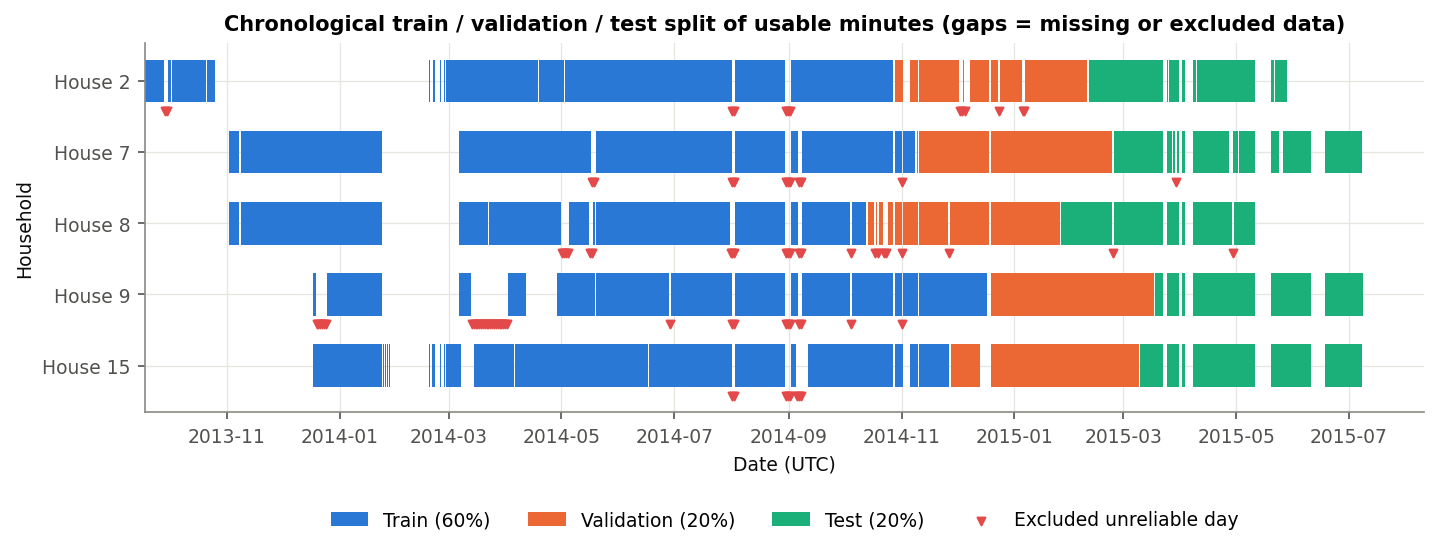

In [4]:
feas = w.feasibility_table(d["minute"], d["flags"], d["splits"], d["cuts"])
display(feas.set_index("house").T)
display(Image(filename=str(w.fig_split_timeline(d))))

**What the evaluation can and cannot claim.**

- **Main evaluation = unseen *time* in the same homes.** One model is trained on all five houses' training periods
  and scored on each house's later test period. It has seen these homes' machines before, so this measures how
  well it tracks *future* use in *known* homes.
- **Cross-household check = leave-one-house-out.** For each house, a model is trained on the *other four* houses'
  training periods, early-stopped on *their* validation periods, and its own "on" threshold τ is chosen on *those
  four* validation periods only. It is then scored on the held-out house's same test period. The held-out house
  contributes nothing to fitting, early stopping or τ. Only these numbers speak to a never-seen home.

> **Limitation:** the test periods all fall in late winter–summer 2015 while training covers autumn 2013–autumn
> 2014. Seasonal differences (heating loads, laundry habits) are therefore part of the test, which is realistic,
> but seasonal effects cannot be separated from model error.

> **Class balance:** the machine is active (> 20 W) in only about 3–10% of test minutes (table above). An
> "always off" prediction is therefore right ~95% of the time and has a low MAE — metrics must be read with that in mind.

## 2 · Inputs, target, baselines and model

- **Target:** 1-minute mean WM power (W), never used as an input (no lagged target values).
- **Input:** 1-minute mean aggregate power (W) only, summarised over windows around each minute:
  - values and rolling statistics over the past, future and centred 5/15/30/60 minutes (mean, std, min, max)
  - the load above the local 2-hour minimum
  - the number of minutes in ±60 min with a step above 1.5 kW (the heater signature)
  - hour of day and weekend flag
- **Prediction timing:** the main model uses aggregate up to **60 minutes after** the minute being estimated, so an
  estimate exists 60 min after the fact. This is suitable for after-the-fact disaggregation (bills, feedback,
  programme evaluation), not for instant control. A **causal** variant (past 60 min only) is trained as a check.
- **Baselines:** (1) *always off* (0 W); (2) *hour-of-day profile* — mean WM power for each local hour, from that
  house's own training period.
- **Model:** LightGBM gradient-boosted trees, squared-error loss, early stopping on the **validation** period.
  Predictions are clipped to [0 W, aggregate], and values at or below an "on" level τ are set to 0. τ is chosen
  on the validation period to maximise minute-level F1 — the test period is never used for any choice.

> **Assumption:** the Phase 2 activity threshold (20 W) defines a *truly active* minute; the Phase 2 cycle rule
> (pauses ≤ 15 min joined; 10–300 min; ≥ 0.05 kWh; peak > 200 W) defines a *true wash cycle* for event metrics.

**Cycle matching (fixed before evaluation).** The same cycle rule is applied to the predicted series (with τ).
Predicted and actual cycles are then matched **one-to-one**: temporal IoU = minutes in both ÷ minutes in either; a
pair is eligible only if IoU ≥ 0.5; pairs are taken greedily from the highest IoU down, and each cycle can be used
once. Cycle precision = matched ÷ predicted cycles; recall = matched ÷ actual cycles. A looser one-to-one
"any overlap" criterion is reported only as a sensitivity check.

The next cell runs the whole pipeline (≈ 2 minutes: 7 model fits including the leave-one-house-out models)
and writes every table and figure.

In [5]:
res = w.run_all(verbose=False)
print("Chosen on-threshold tau (W), within-house model:", res["tau"])
print("Fold-specific tau (W) for leave-one-house-out, keyed by held-out house:", res["loho_tau"])
print("Best iterations:", res["run_info"]["best_iterations"])
display(res["thr"].round(3))
display(res["loho_thr"][res["loho_thr"]["selected"]].round(3))

Chosen on-threshold tau (W), within-house model: 50.0
Fold-specific tau (W) for leave-one-house-out, keyed by held-out house: {2: 50.0, 7: 50.0, 8: 50.0, 9: 50.0, 15: 50.0}
Best iterations: {'within_house': 367, 'causal': 220, 'loho_holdout_2': 761, 'loho_holdout_7': 284, 'loho_holdout_8': 372, 'loho_holdout_9': 458, 'loho_holdout_15': 380}


,tau_W,precision,recall,F1
0,10,0.210,0.920,0.342
1,20,0.283,0.860,0.426
2,50,0.391,0.634,0.484
3,100,0.385,0.378,0.382
4,150,0.394,0.308,0.346
5,200,0.423,0.286,0.341
6,300,0.489,0.257,0.337
7,500,0.607,0.215,0.318


,held_out_house,tau_W,precision,recall,F1,selected
2,2,50,0.452,0.736,0.560,True
10,7,50,0.364,0.625,0.460,True
18,8,50,0.392,0.627,0.482,True
26,9,50,0.415,0.681,0.516,True
34,15,50,0.381,0.611,0.470,True


## 3 · Results

### Minute-level metrics on the test period (within-house, unseen time)

- **MAE / RMSE (W):** average and large-error-weighted error of the power estimate. RMSE punishes missing a
  2 kW heater block much more than MAE does, which matters because those blocks carry most of the energy.
- **MAE active:** MAE on minutes when the machine was really on — the minutes that matter.
- **Energy error %:** total predicted vs actual WM energy over the test period (what a bill-level insight needs).
- **Precision / recall / F1:** whether the model says "on" (prediction > τ) when the machine is on (actual > 20 W).

In [6]:
m = res["metrics"]
cols = ["model", "house", "MAE_W", "RMSE_W", "MAE_active_W", "energy_error_pct", "precision", "recall", "F1"]
display(m[m.split == "test"][cols].round(3))

,model,house,MAE_W,RMSE_W,MAE_active_W,energy_error_pct,precision,recall,F1
24,LightGBM (centered ±60 min),2,24.548,136.980,261.195,9.277,0.298,0.408,0.344
25,LightGBM (centered ±60 min),7,31.704,156.179,235.223,-15.453,0.658,0.688,0.673
26,LightGBM (centered ±60 min),8,25.356,141.397,359.798,10.452,0.403,0.837,0.544
27,LightGBM (centered ±60 min),9,17.932,114.522,294.654,8.347,0.351,0.677,0.463
28,LightGBM (centered ±60 min),15,7.633,72.330,226.315,-34.227,0.885,0.546,0.675
29,LightGBM (centered ±60 min),pooled,21.629,128.287,263.978,-5.517,0.491,0.640,0.556
30,"LightGBM (causal, past 60 min)",2,27.935,154.115,297.811,10.084,0.265,0.363,0.306
31,"LightGBM (causal, past 60 min)",7,36.130,174.171,267.269,-23.003,0.614,0.619,0.617
32,"LightGBM (causal, past 60 min)",8,31.862,174.145,443.648,9.536,0.369,0.798,0.505
33,"LightGBM (causal, past 60 min)",9,19.766,125.982,327.390,3.315,0.326,0.628,0.429


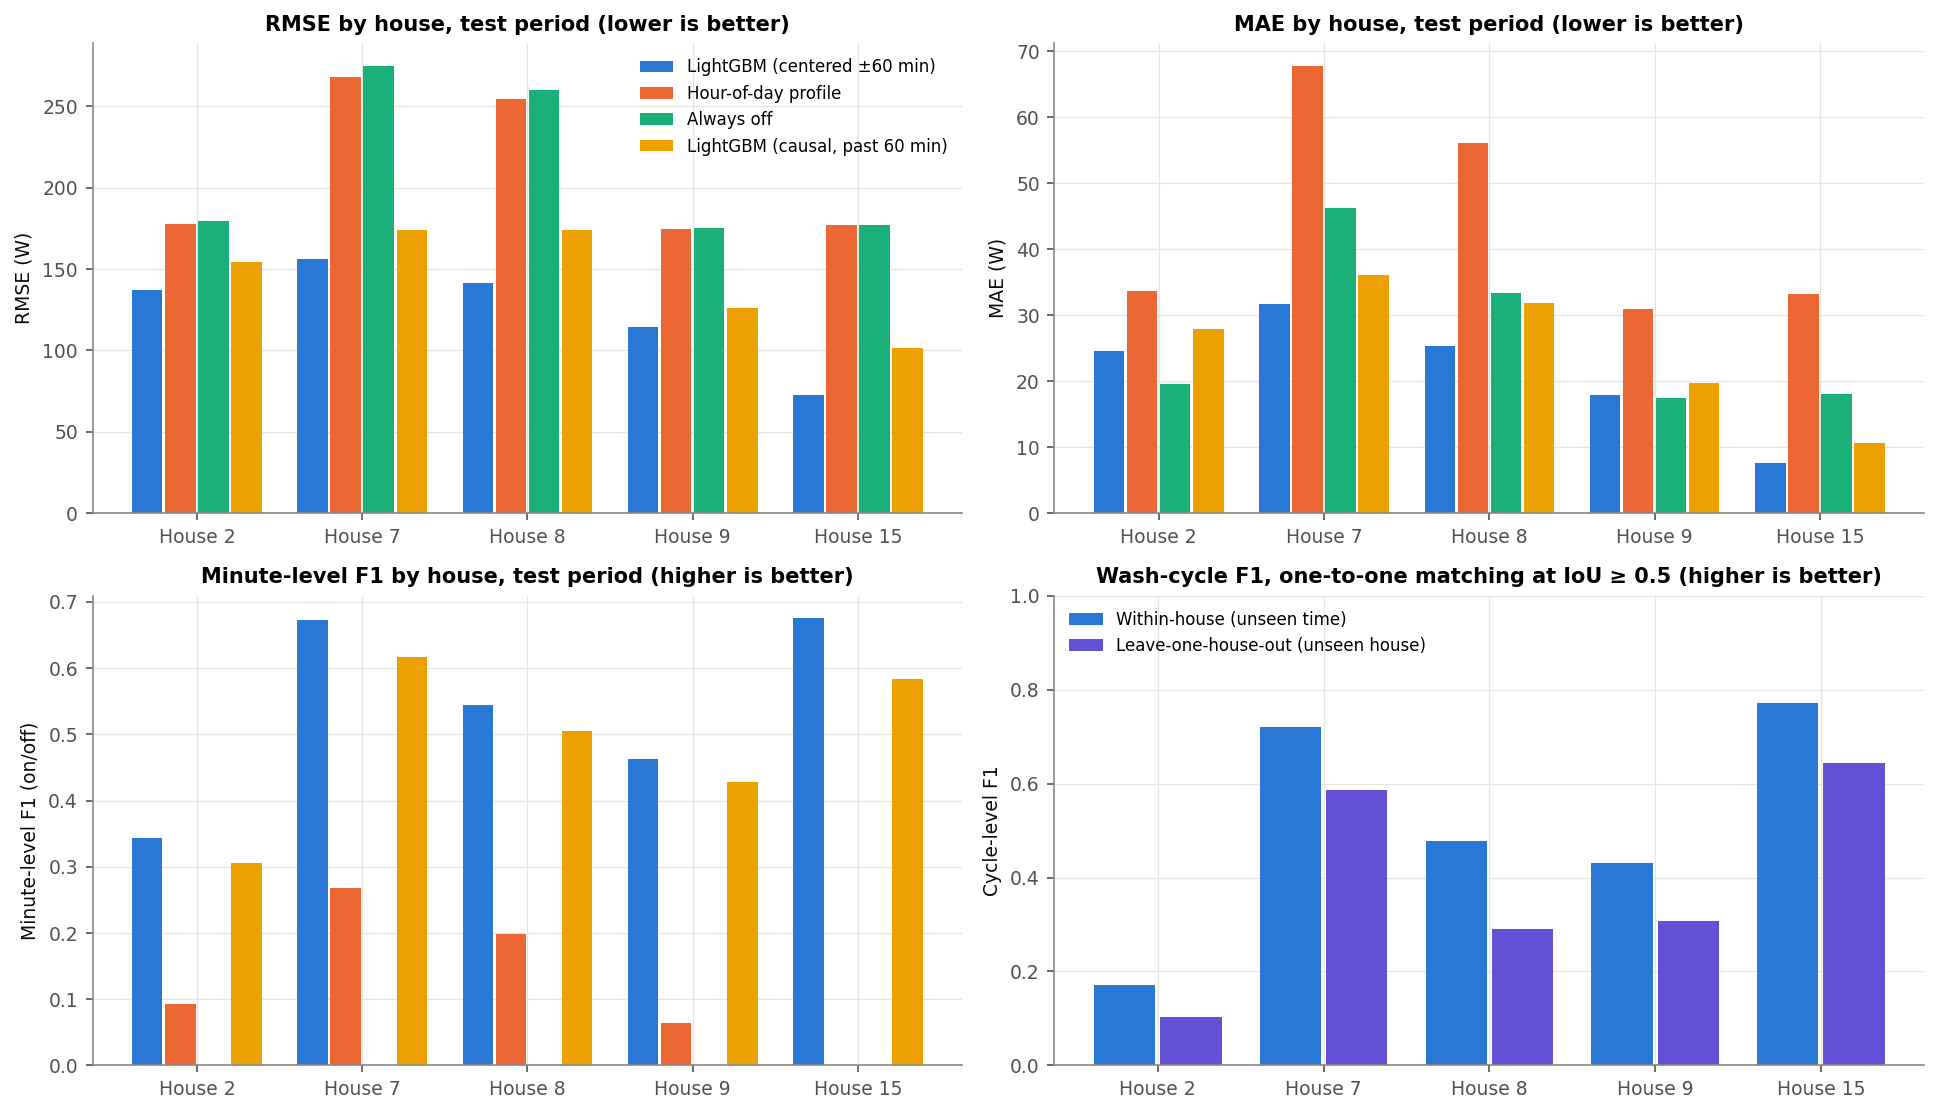

In [7]:
display(Image(filename=str(res["figs"][5])))

**Interpretation.** Against both baselines, the model cuts RMSE and active-minute MAE in every house and is
the only method with useful on/off detection. Plain MAE is the exception: in Houses 2 and 9, *always off*
has a slightly lower MAE than the model, because it is never wrong during the ~95% of off minutes while the model
pays for its false "on" estimates (mostly other appliances, see §4). This is a known property of MAE on sparse appliances and is exactly
why MAE alone would be a misleading headline. The causal variant is consistently a little worse than the
centred model on RMSE and F1 in every house — seeing what the aggregate does *after* a minute helps.

### Actual vs predicted

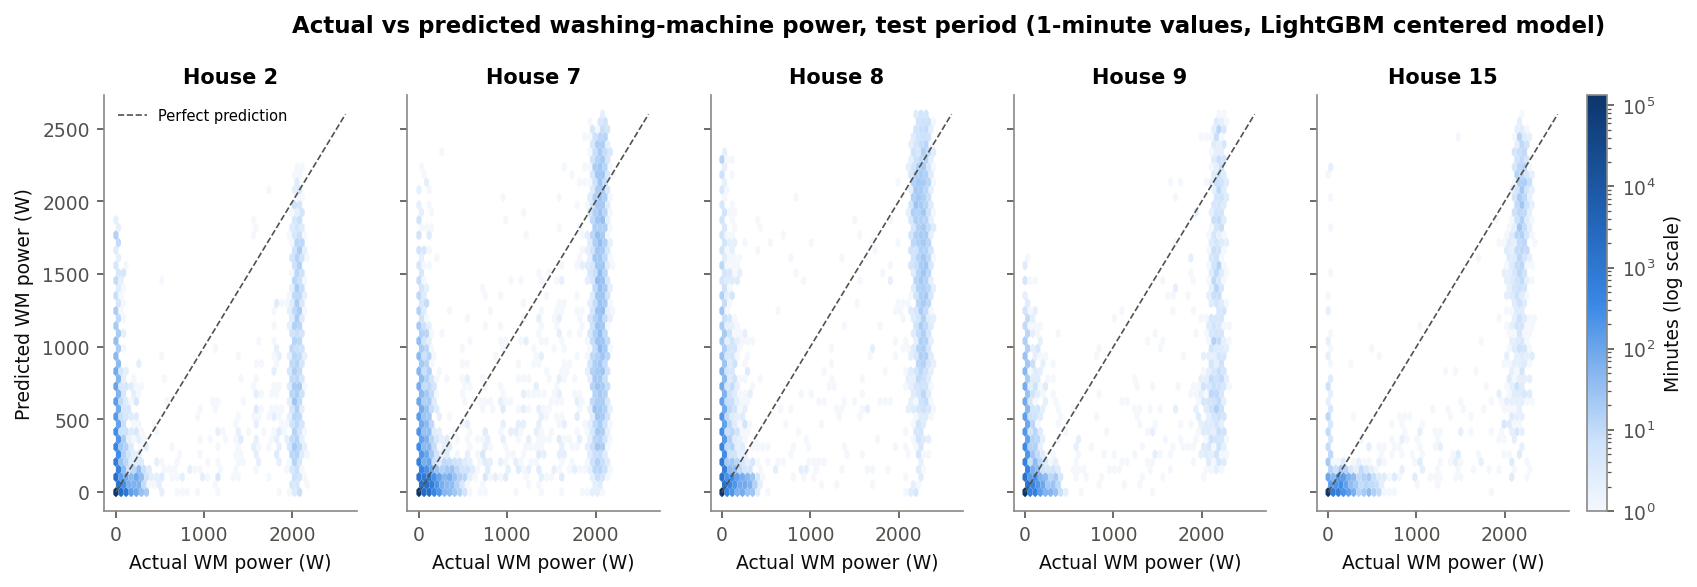

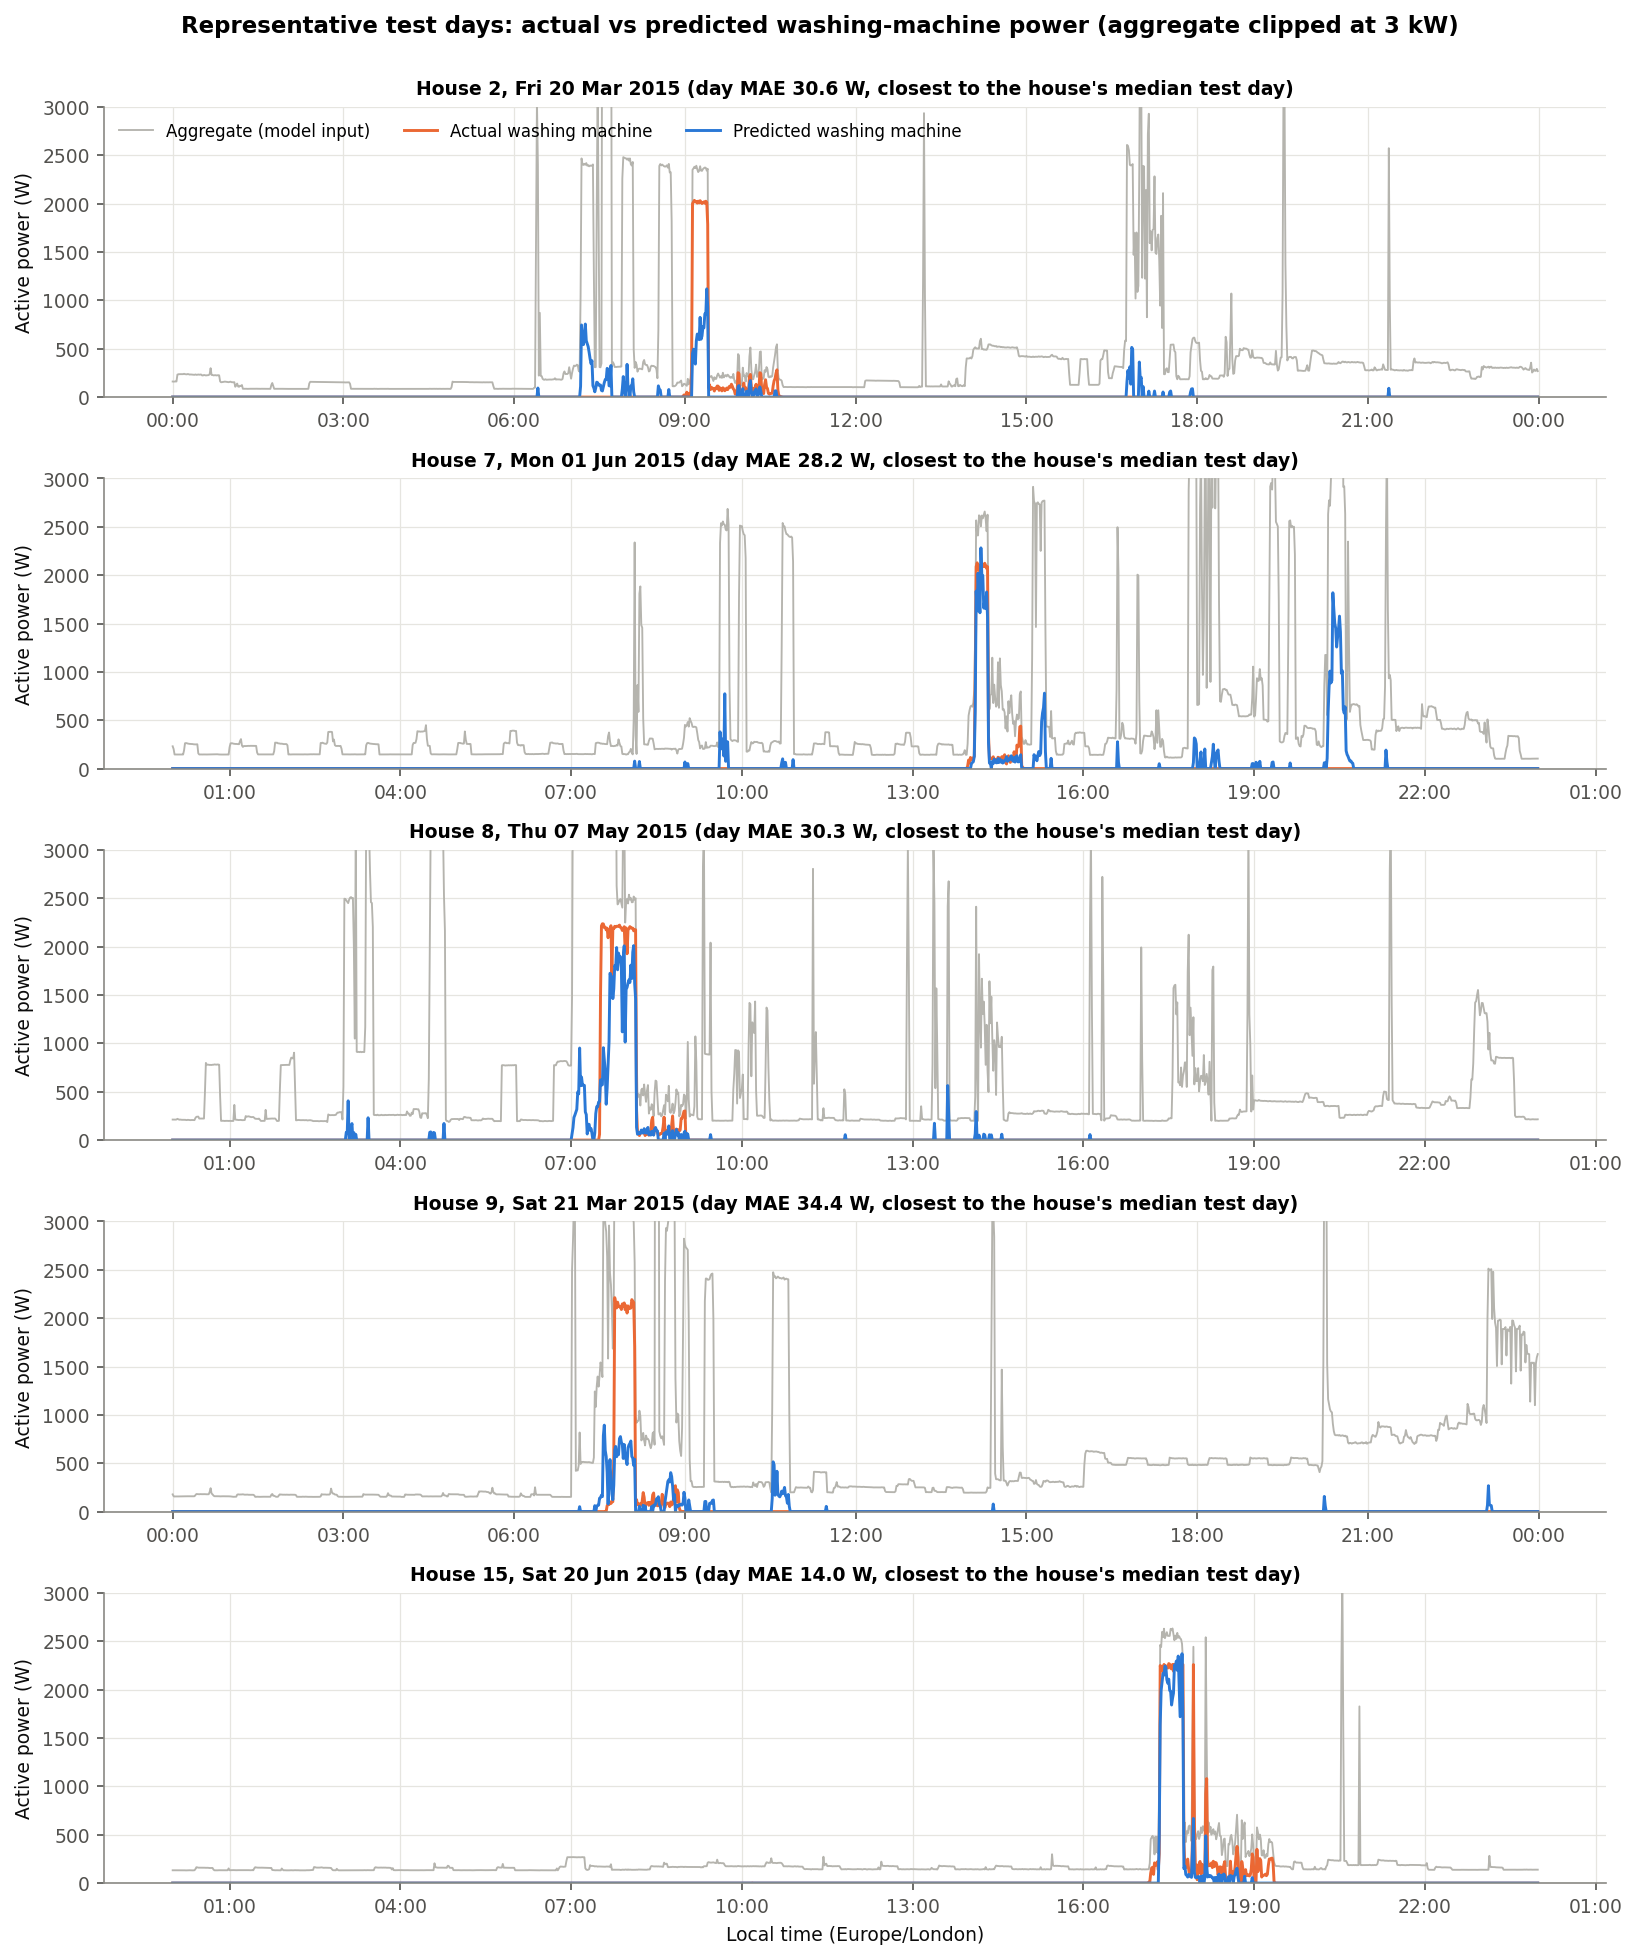

,house,day_local,day_MAE_W,median_day_MAE_W,candidate_days
0,2,2015-03-20 00:00:00+00:00,30.6,30.6,43
1,7,2015-06-01 00:00:00+01:00,28.2,28.2,93
2,8,2015-05-07 00:00:00+01:00,30.3,30.3,61
3,9,2015-03-21 00:00:00+00:00,34.4,34.1,28
4,15,2015-06-20 00:00:00+01:00,14.0,14.0,57


In [8]:
display(Image(filename=str(res["figs"][2])))
display(Image(filename=str(res["figs"][4])))
display(res["days"])

**Interpretation.** Most minutes sit at (0, 0). Heater minutes (~2–2.3 kW actual) form a vertical band: the model
usually recognises them but often under-estimates them. The low-power tail (actual 20–500 W) is mostly predicted
near zero. The representative days — chosen as each house's *median*-error test day, not a best case — show the
same pattern: the heater block is usually found but often under-sized; the long low-power tail is largely
missed; and other large loads sometimes trigger smaller false estimates.

### Cycle-level detection and per-cycle energy

Primary: one-to-one matching, IoU >= 0.5


,setting,house,true_cycles,pred_cycles,matched_cycles,event_precision,event_recall,event_F1
0,within-house,2,64,159,19,0.119,0.297,0.170
1,within-house,7,202,301,181,0.601,0.896,0.720
2,within-house,8,73,178,60,0.337,0.822,0.478
3,within-house,9,50,150,43,0.287,0.860,0.430
4,within-house,15,45,43,34,0.791,0.756,0.773
5,leave-one-house-out,2,64,149,11,0.074,0.172,0.103
6,leave-one-house-out,7,202,364,166,0.456,0.822,0.587
7,leave-one-house-out,8,73,292,53,0.182,0.726,0.290
8,leave-one-house-out,9,50,216,41,0.190,0.820,0.308
9,leave-one-house-out,15,45,42,28,0.667,0.622,0.644


Sensitivity: one-to-one matching, any overlap


,setting,house,true_cycles,pred_cycles,matched_cycles,event_precision,event_recall,event_F1
20,within-house,2,64,159,61,0.384,0.953,0.547
21,within-house,7,202,301,195,0.648,0.965,0.775
22,within-house,8,73,178,70,0.393,0.959,0.558
23,within-house,9,50,150,48,0.320,0.960,0.480
24,within-house,15,45,43,38,0.884,0.844,0.864
25,leave-one-house-out,2,64,149,51,0.342,0.797,0.479
26,leave-one-house-out,7,202,364,192,0.527,0.950,0.678
27,leave-one-house-out,8,73,292,70,0.240,0.959,0.384
28,leave-one-house-out,9,50,216,49,0.227,0.980,0.368
29,leave-one-house-out,15,45,42,37,0.881,0.822,0.851


,house,true_cycles,actual_kwh_total,pred_kwh_total,median_abs_pct_err,false_detection_pred_kwh,total_pred_kwh_test
0,2,64,41.980,20.149,51.568,19.699,46.076
1,7,202,114.939,76.247,34.409,13.659,97.555
2,8,73,74.656,56.066,27.039,17.148,83.102
3,9,50,36.527,21.551,45.007,12.135,39.775
4,15,45,40.860,26.209,39.435,0.719,27.206


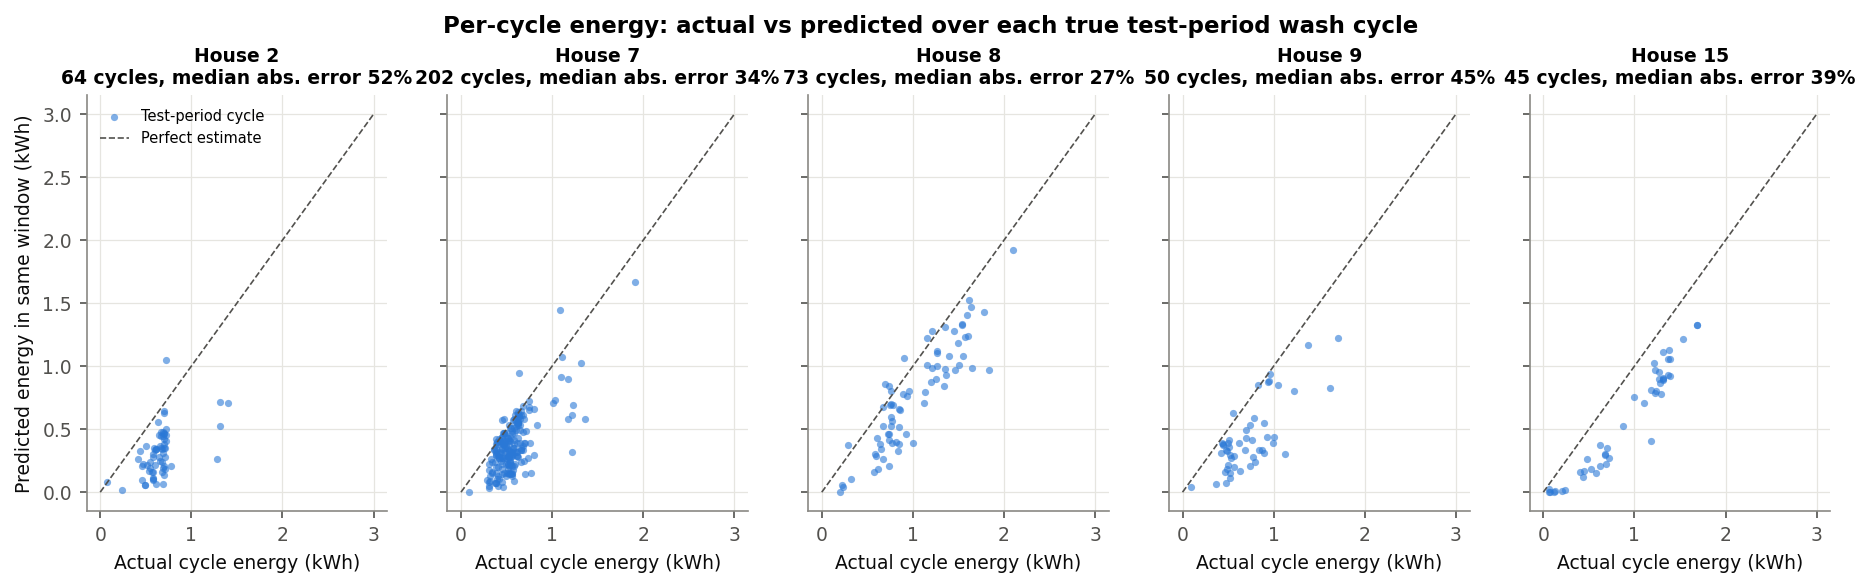

In [9]:
ev = res["events"]
cols_ev = ["setting", "house", "true_cycles", "pred_cycles", "matched_cycles", "event_precision", "event_recall", "event_F1"]
print("Primary: one-to-one matching, IoU >= 0.5")
display(ev[ev.criterion == "one-to-one IoU>=0.5"][cols_ev].round(3))
print("Sensitivity: one-to-one matching, any overlap")
display(ev[ev.criterion == "one-to-one any overlap"][cols_ev].round(3))
display(res["cyc_stats"])
display(Image(filename=str(res["figs"][3])))

**Interpretation.** With one-to-one matching at IoU ≥ 0.5, most true cycles are matched, but clearly fewer
than "any overlap" suggests: many predicted cycles touch the right wash yet cover only its heater block, so their
IoU falls below 0.5. House 2 (long ~1.5 h programmes) is hit hardest. Many predicted cycles are not washing at all
(moderate precision). Per cycle, the model under-estimates energy — most points sit below the diagonal,
because the low-power tail is missed. Total test-period energy nevertheless comes out close in some houses
because the energy assigned to false detections roughly offsets the under-estimate. **That agreement is partly
coincidental**: a utility using the totals would be counting dishwasher and kettle energy as washing.

### Cross-household check (leave-one-house-out)

In [10]:
display(res["loho"].round(3))

,setting,held_out_house,model,tau_W,minutes,MAE_W,RMSE_W,MAE_active_W,energy_true_kWh,energy_pred_kWh,energy_error_pct,precision,recall,F1
0,leave-one-house-out,2,LightGBM (centered ±60 min),50.0,128994,29.138,168.920,339.160,42.165,40.073,-4.961,0.270,0.358,0.308
1,leave-one-house-out,2,Hour-of-day profile (other houses),50.0,128994,40.437,179.026,387.616,42.165,50.423,19.586,0.043,0.076,0.055
2,leave-one-house-out,2,Always off,50.0,128994,19.612,179.752,412.197,42.165,0.000,-100.000,NaN,0.000,0.000
3,leave-one-house-out,7,LightGBM (centered ±60 min),50.0,149777,41.108,188.059,280.317,115.385,100.770,-12.666,0.563,0.614,0.587
4,leave-one-house-out,7,Hour-of-day profile (other houses),50.0,149777,61.155,272.255,450.804,115.385,48.050,-58.357,0.109,0.046,0.065
5,leave-one-house-out,7,Always off,50.0,149777,46.223,275.018,471.240,115.385,0.000,-100.000,NaN,0.000,0.000
6,leave-one-house-out,8,LightGBM (centered ±60 min),50.0,135601,58.479,246.529,629.958,75.239,109.608,45.680,0.239,0.762,0.364
7,leave-one-house-out,8,Hour-of-day profile (other houses),50.0,135601,52.313,259.716,885.383,75.239,46.395,-38.336,0.092,0.205,0.127
8,leave-one-house-out,8,Always off,50.0,135601,33.291,260.400,902.442,75.239,0.000,-100.000,NaN,0.000,0.000
9,leave-one-house-out,9,LightGBM (centered ±60 min),50.0,126743,27.354,151.912,337.244,36.711,54.347,48.038,0.287,0.722,0.411


**Interpretation.** Scored on a home it has never seen, the model still beats both baselines on RMSE (only just
in House 8). Every fold selected the same τ as the within-house model (shown above), so the minute metrics are
not affected by the threshold protocol. Cycle F1 falls in every house compared with the within-house model, and
total-energy errors become large in Houses 8, 9 and 15: the held-out house's other appliances, and its washing
machine's exact signature, were never in training. This is the only evidence here about new homes, and it
comes from just five houses in one UK region.

## 4 · Error analysis

,band,model,minutes,share_of_test_pct,MAE_W,bias_W
0,off (<=20 W),LightGBM (centered ±60 min),644493,95.0,8.9,8.6
1,off (<=20 W),Hour-of-day profile,644493,95.0,20.6,20.5
2,off (<=20 W),Always off,644493,95.0,0.1,-0.1
3,low-power tail (20-1000 W),LightGBM (centered ±60 min),26603,3.9,114.3,-37.5
4,low-power tail (20-1000 W),Hour-of-day profile,26603,3.9,91.4,-73.4
5,low-power tail (20-1000 W),Always off,26603,3.9,121.4,-121.4
6,heating (>1000 W),LightGBM (centered ±60 min),7353,1.1,805.6,-758.1
7,heating (>1000 W),Hour-of-day profile,7353,1.1,2025.1,-2025.1
8,heating (>1000 W),Always off,7353,1.1,2084.8,-2084.8
9,"active, other load <500 W",LightGBM (centered ±60 min),15304,2.3,226.4,-208.7


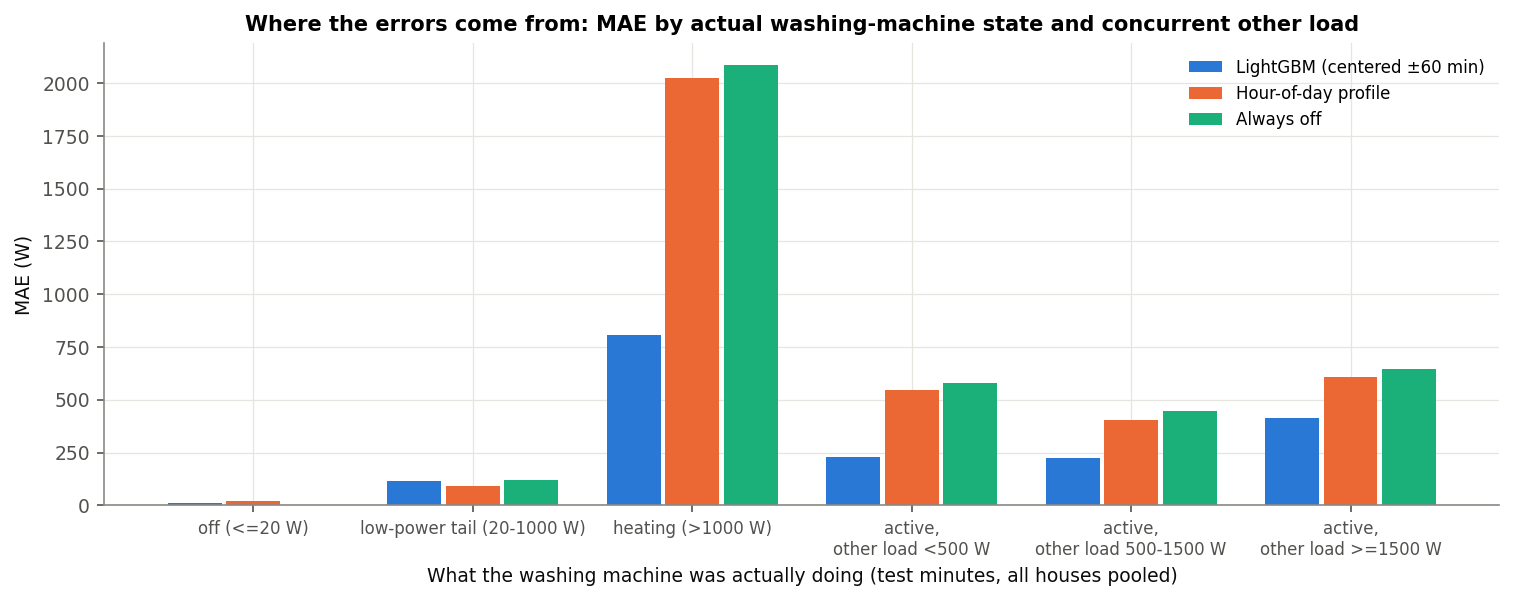

In [11]:
display(res["bands"].round(1))
display(Image(filename=str(res["figs"][7])))

**Interpretation.** Errors concentrate in the ~5% of minutes when the machine is on.
- **Heater minutes** are the largest error source per minute: the model finds them but under-sizes them,
  especially when another big load overlaps.
- **Low-power tail** minutes (drum, rinse, spin at tens to hundreds of watts) are barely better than *always off*
  and worse than the hour profile, because a few hundred watts is indistinguishable from the fridge, lights and
  electronics in the aggregate.
- **Overlap:** MAE during active minutes rises when ≥ 1.5 kW of other load is running at the same time.

In [12]:
fp = res["fp"]
print("Pure false detections (unmatched predicted cycles overlapping no WM activity) by attributed cause (a metered appliance is named only if its own energy in the window")
print("is at least half of the falsely predicted WM energy):")
display(fp.groupby(["attributed_to"]).agg(count=("house", "size"), predicted_kwh=("pred_energy_kwh", "sum"))
          .sort_values("count", ascending=False).round(2))
display(fp.groupby(["house", "attributed_to"]).size().unstack(fill_value=0))
print("True cycles by matching outcome (IoU >= 0.5):")
display(res["missed_vs_detected"])
display(res["missed"].groupby(["house", "status"]).size().unstack(fill_value=0))

Pure false detections (unmatched predicted cycles overlapping no WM activity) by attributed cause (a metered appliance is named only if its own energy in the window
is at least half of the falsely predicted WM energy):


,count,predicted_kwh
attributed_to,,
Dishwasher,132,16.49
unmetered or unclear,111,23.59
Kettle,55,5.42
Tumble Dryer,55,9.98
Washer Dryer,19,5.71
Microwave,16,1.36
Television Site,3,0.23
Freezer(1),2,0.15
Fridge-Freezer,2,0.20


attributed_to,Dishwasher,Freezer(1),Fridge-Freezer,Kettle,Microwave,Television Site,Toaster,Tumble Dryer,Washer Dryer,unmetered or unclear
house,,,,,,,,,,
2,45,0,2,11,2,0,0,0,0,28
7,31,2,0,3,0,0,2,51,0,9
8,0,0,0,17,11,2,0,0,8,68
9,56,0,0,24,3,1,0,0,11,5
15,0,0,0,0,0,0,0,4,0,1


True cycles by matching outcome (IoU >= 0.5):


,status,cycles,median_energy_kwh,heated_pct,median_duration_min,median_other_load_w,median_best_iou,median_overlapping_pred
0,matched,337,0.625,100.000,68.0,918.682,0.871,1.0
1,no overlap at all,13,0.202,61.538,47.0,478.574,0.000,0.0
2,"overlapped, below match IoU",84,0.611,97.619,88.5,862.260,0.316,1.0


status,no overlap at all,"overlapped, below match IoU"
house,,
2,1,44
7,4,17
8,1,12
9,1,6
15,6,5


,case,house,start_utc,end_utc
0,Missed cycle (largest-energy true cycle with n...,7,2015-04-15 14:33:00+00:00,2015-04-15 15:27:00+00:00
1,Found but badly aligned (largest-energy true c...,2,2015-02-23 12:15:00+00:00,2015-02-23 15:55:00+00:00
2,False detection (largest with no WM activity; ...,2,2015-03-28 04:00:00+00:00,2015-03-28 08:41:00+00:00
3,Overlapping loads (true cycle with highest con...,8,2015-02-24 05:15:00+00:00,2015-02-24 05:44:00+00:00


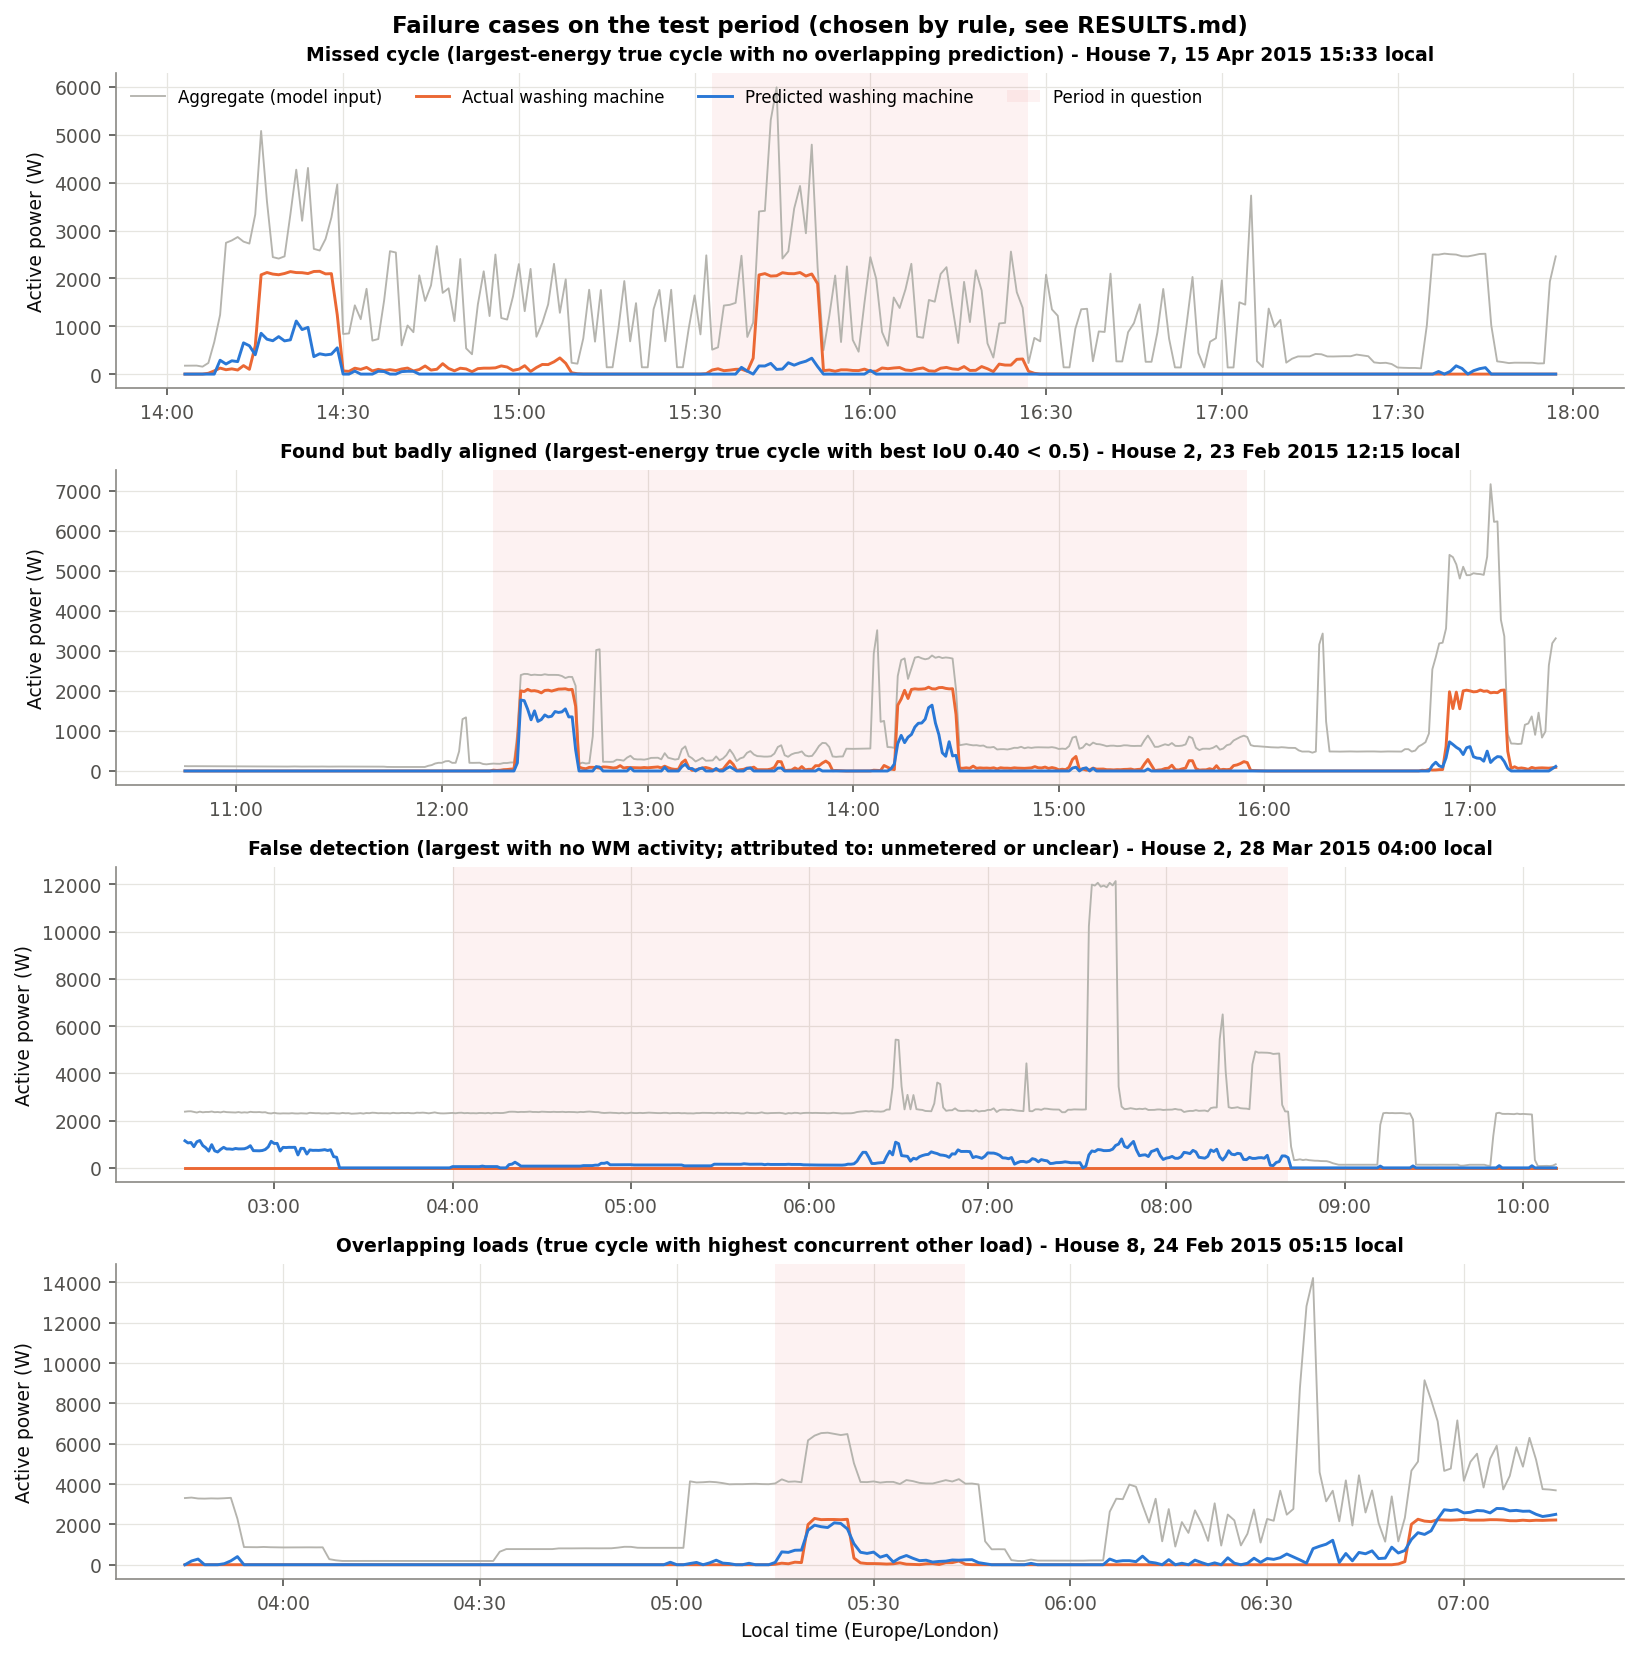

In [13]:
display(pd.DataFrame(res["cases"], columns=["case", "house", "start_utc", "end_utc"]))
display(Image(filename=str(res["figs"][6])))

**Failure cases (chosen by rule, not by eye).**

1. **Missed cycle** — the largest-energy true cycle with no overlapping prediction at all: its heater block
   coincides with a busy stretch of several-kW loads, so the WM step is buried.
2. **Found but badly aligned** — the largest-energy true cycle that is overlapped but not matched (IoU < 0.5): the
   model predicts the heater blocks, but the Phase 2 rule joins a long stretch (probably two loads run back to back)
   into one "true cycle", so no single predicted cycle covers half of it. Part of this failure lies in the
   ground-truth definition, not only in the model.
3. **False detection** — the largest predicted cycle that overlaps no real WM activity: a steady ~2.3 kW load
   running for hours overnight, on no sub-meter (the attribution in the title), is read as a long heater block.
4. **Overlapping loads** — the true cycle with the highest concurrent other load: the model still tracks the heater
   but spreads energy into the surrounding busy period.

Among false detections that can be traced to a sub-metered appliance, **dishwashers** are the most common cause,
followed by **kettles** and **tumble dryers** — all with ~2 kW heating elements. Houses 8 and 9 also own a separate
**washer-dryer**, which the model reasonably but wrongly reads as the washing machine. A large group cannot be
attributed to any sub-meter (unmetered loads, especially in House 8). Unmatched true cycles are of two kinds:
those with **no overlapping prediction** are small and often unheated (cold or short washes whose only signature is
the weak tail); those **overlapped below IoU 0.5** are ordinary heated cycles whose predicted cycle stops after the
heater block, because the low-power tail is missed.

> **Limitation:** the "top other appliance" attribution only sees sub-metered appliances. Unmetered loads (electric
> showers, cookers, storage heating) cannot be named and appear as "no metered appliance".

## 5 · Saved outputs

Every table above is in `outputs/tables/phase3/`; `17_key_numbers.csv` holds the headline numbers quoted in
`phase3/RESULTS.md`.

In [14]:
print("\n".join(str(p.relative_to(w.ROOT)) for p in sorted(w.TAB_DIR.glob("*.csv"))))
print("\n".join(str(p.relative_to(w.ROOT)) for p in res["figs"]))
pd.read_csv(w.TAB_DIR / "17_key_numbers.csv")

outputs/tables/phase3/01_household_selection.csv
outputs/tables/phase3/02_feasibility_and_split.csv
outputs/tables/phase3/03_excluded_unreliable_days.csv
outputs/tables/phase3/04_frozen_aggregate_wm_evidence.csv
outputs/tables/phase3/05_threshold_selection_val.csv
outputs/tables/phase3/05b_loho_threshold_selection.csv
outputs/tables/phase3/06_metrics_within_house.csv
outputs/tables/phase3/07_metrics_leave_one_house_out.csv
outputs/tables/phase3/08_event_metrics.csv
outputs/tables/phase3/09_cycle_energy_by_house.csv
outputs/tables/phase3/10_test_true_cycles.csv
outputs/tables/phase3/11_false_detections_attributed.csv
outputs/tables/phase3/12_missed_cycles.csv
outputs/tables/phase3/12b_missed_vs_detected.csv
outputs/tables/phase3/13_error_by_state_and_overlap.csv
outputs/tables/phase3/14_feature_importance.csv
outputs/tables/phase3/15_typical_days.csv
outputs/tables/phase3/16_failure_cases.csv
outputs/tables/phase3/17_key_numbers.csv
outputs/figures/phase3/01_split_timeline.png
outputs/f

,metric,value
0,tau_W,50.0
1,loho_tau_W__held_out_house_2,50.0
2,loho_tau_W__held_out_house_7,50.0
3,loho_tau_W__held_out_house_8,50.0
4,loho_tau_W__held_out_house_9,50.0
...,...,...
78,pure_false_detections_attributed__Fridge-Freezer,2.0
79,pure_false_detections_attributed__Freezer(1),2.0
80,pure_false_detections_attributed__Toaster,2.0
81,pure_false_detections_total,397.0
